In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATOS = RAIZ / "data"
FIGURAS = RAIZ / "docs" / "ppt" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

AZUL = "#2a78d6"
NARANJA = "#eb6834"
GRIS = "#b5b4ad"
TEXTO = "#212121"
TEXTO_2 = "#52514e"
REJILLA = "#e4e3de"
FONDO = "#fcfcfb"
TAM = (9, 5.03)
T = 13

plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 200,
    "figure.facecolor": FONDO,
    "axes.facecolor": FONDO,
    "font.family": "DejaVu Sans",
    "font.size": T,
    "axes.edgecolor": REJILLA,
    "axes.labelcolor": TEXTO_2,
    "xtick.color": TEXTO_2,
    "ytick.color": TEXTO_2,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": REJILLA,
    "grid.linewidth": 0.8,
    "legend.frameon": False,
})

miles = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", " "))
soles = lambda v: f"S/ {v:,.2f}".replace(",", "X").replace(".", ",").replace("X", " ")

def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(FIGURAS / nombre, facecolor=FONDO)
    plt.show()

In [2]:
crudo = pd.read_csv(DATOS / "crudos" / "mercadolibre_raw.csv", encoding="utf-8-sig", parse_dates=["fecha_extraccion"])
limpio = pd.read_csv(DATOS / "limpios" / "mercadolibre_limpio.csv", encoding="utf-8-sig", parse_dates=["fecha_extraccion"])
calidad = pd.read_csv(DATOS / "calidad" / "calidad_por_columna.csv", encoding="utf-8-sig")
diagnostico = pd.read_csv(DATOS / "calidad" / "diagnostico_columnas.csv", encoding="utf-8-sig")
revision = pd.read_csv(DATOS / "calidad" / "filas_para_revision.csv", encoding="utf-8-sig")
duplicados = pd.read_csv(DATOS / "calidad" / "duplicados_retirados.csv", encoding="utf-8-sig")
excluidos = pd.read_csv(DATOS / "calidad" / "precios_excluidos.csv", encoding="utf-8-sig")

assert len(crudo) == len(revision) + len(duplicados) + len(excluidos) + len(limpio)
len(crudo), len(revision), len(duplicados), len(excluidos), len(limpio)

(5080, 56, 605, 7, 4412)

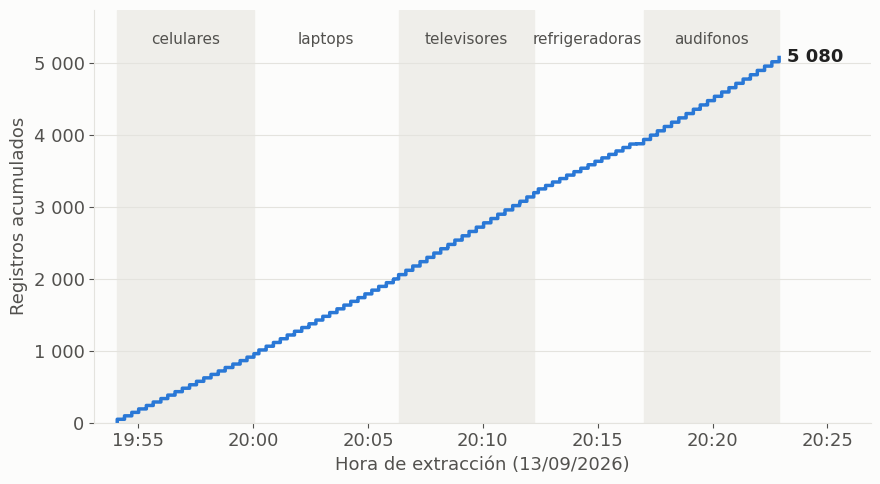

In [3]:
serie = crudo.sort_values("fecha_extraccion").reset_index(drop=True)
serie["acumulado"] = np.arange(1, len(serie) + 1)
tramos = serie.groupby("categoria")["fecha_extraccion"].agg(["min", "max"]).sort_values("min")

fig, ax = plt.subplots(figsize=TAM)
for i, (cat, fila) in enumerate(tramos.iterrows()):
    if i % 2 == 0:
        ax.axvspan(fila["min"], fila["max"], color="#efeeea", zorder=0)
    medio = fila["min"] + (fila["max"] - fila["min"]) / 2
    ax.text(medio, len(serie) * 1.03, cat, ha="center", va="bottom", fontsize=T - 2, color=TEXTO_2)
ax.step(serie["fecha_extraccion"], serie["acumulado"], where="post", color=AZUL, linewidth=2.5, zorder=2)
ax.annotate(f"{len(serie):,}".replace(",", " "), xy=(serie["fecha_extraccion"].iloc[-1], len(serie)),
            xytext=(6, 0), textcoords="offset points", ha="left", va="center", fontsize=T, fontweight="bold", color=TEXTO)
ax.set_xlim(serie["fecha_extraccion"].min() - pd.Timedelta(minutes=1), serie["fecha_extraccion"].max() + pd.Timedelta(minutes=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.xaxis.set_major_locator(mdates.MinuteLocator(byminute=range(0, 60, 5)))
ax.yaxis.set_major_formatter(miles)
ax.set_ylim(0, len(serie) * 1.13)
ax.set_xlabel("Hora de extracción (13/09/2026)")
ax.set_ylabel("Registros acumulados")
ax.grid(axis="y")
ax.set_axisbelow(True)
guardar(fig, "progreso_extraccion.png")

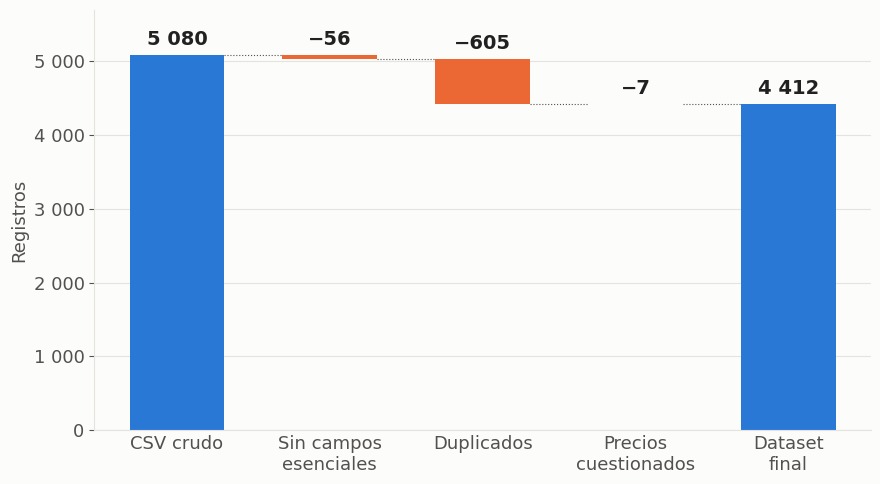

In [4]:
pasos = [
    ("CSV crudo", len(crudo), "total"),
    ("Sin campos\nesenciales", -len(revision), "resta"),
    ("Duplicados", -len(duplicados), "resta"),
    ("Precios\ncuestionados", -len(excluidos), "resta"),
    ("Dataset\nfinal", len(limpio), "total"),
]
fig, ax = plt.subplots(figsize=TAM)
nivel = 0
for i, (etiqueta, valor, tipo) in enumerate(pasos):
    if tipo == "total":
        base, alto, color, nivel = 0, valor, AZUL, valor
        texto = f"{valor:,}".replace(",", " ")
    else:
        base, alto, color = nivel + valor, -valor, NARANJA
        nivel += valor
        texto = f"−{-valor:,}".replace(",", " ")
    ax.bar(i, alto, bottom=base, color=color, width=0.62)
    ax.text(i, base + alto + 80, texto, ha="center", va="bottom", color=TEXTO, fontsize=T + 1, fontweight="bold")
    if i < len(pasos) - 1:
        ax.plot([i + 0.31, i + 0.69], [nivel, nivel], color=TEXTO_2, linewidth=0.8, linestyle=":")
ax.set_xticks(range(len(pasos)))
ax.set_xticklabels([p[0] for p in pasos])
ax.yaxis.set_major_formatter(miles)
ax.set_ylabel("Registros")
ax.set_ylim(0, len(crudo) * 1.12)
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.tick_params(axis="x", length=0)
guardar(fig, "embudo_limpieza.png")

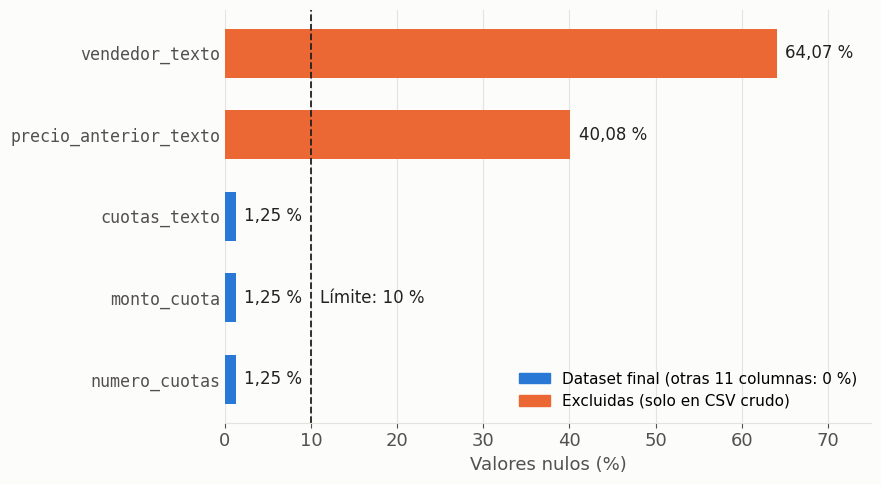

In [5]:
final = calidad[["variable", "porcentaje_nulos"]].assign(grupo="final")
retiradas = (diagnostico[diagnostico["columna"].isin(["precio_anterior_texto", "vendedor_texto"])]
             .rename(columns={"columna": "variable"})[["variable", "porcentaje_nulos"]].assign(grupo="excluida"))
nulos = pd.concat([final[final["porcentaje_nulos"] > 0], retiradas]).sort_values("porcentaje_nulos").reset_index(drop=True)
resto = int((final["porcentaje_nulos"] == 0).sum())

fig, ax = plt.subplots(figsize=TAM)
ax.barh(nulos["variable"], nulos["porcentaje_nulos"], height=0.6,
        color=nulos["grupo"].map({"final": AZUL, "excluida": NARANJA}))
for y, v in enumerate(nulos["porcentaje_nulos"]):
    ax.text(v + 1, y, f"{v:.2f} %".replace(".", ","), va="center", fontsize=T - 1, color=TEXTO)
ax.axvline(10, color=TEXTO, linewidth=1.3, linestyle="--")
ax.text(11, 1.0, "Límite: 10 %", fontsize=T - 1, color=TEXTO, va="center")
ax.set_xlim(0, 75)
ax.set_xlabel("Valores nulos (%)")
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
for lbl in ax.get_yticklabels():
    lbl.set_fontfamily("DejaVu Sans Mono")
    lbl.set_fontsize(T - 1)
handles = [plt.Rectangle((0, 0), 1, 1, color=AZUL), plt.Rectangle((0, 0), 1, 1, color=NARANJA)]
ax.legend(handles, [f"Dataset final (otras {resto} columnas: 0 %)", "Excluidas (solo en CSV crudo)"],
          loc="lower right", fontsize=T - 2)
guardar(fig, "nulos_por_columna.png")

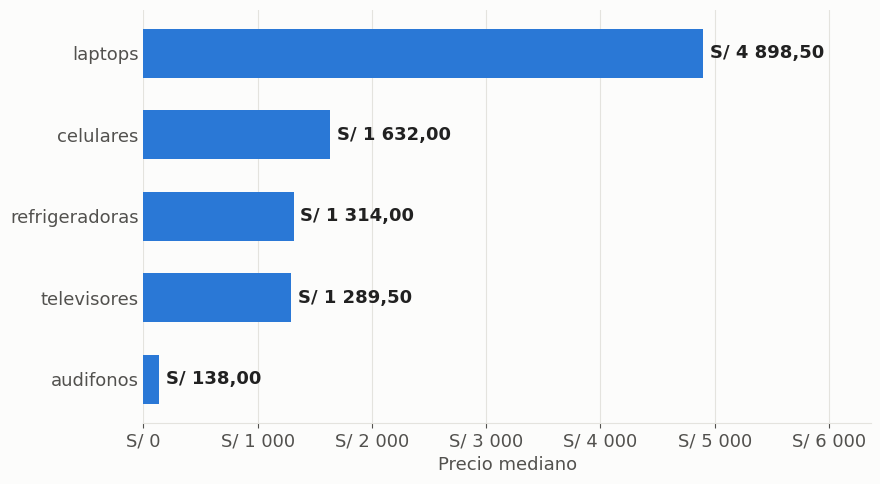

In [6]:
medianas = limpio.groupby("categoria")["precio_actual"].median().sort_values()

fig, ax = plt.subplots(figsize=TAM)
ax.barh(medianas.index, medianas.values, color=AZUL, height=0.6)
for y, v in enumerate(medianas.values):
    ax.text(v + 60, y, soles(v), va="center", fontsize=T, color=TEXTO, fontweight="bold")
ax.set_xlim(0, medianas.max() * 1.3)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"S/ {x:,.0f}".replace(",", " ")))
ax.set_xlabel("Precio mediano")
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
guardar(fig, "precio_mediano_categoria.png")

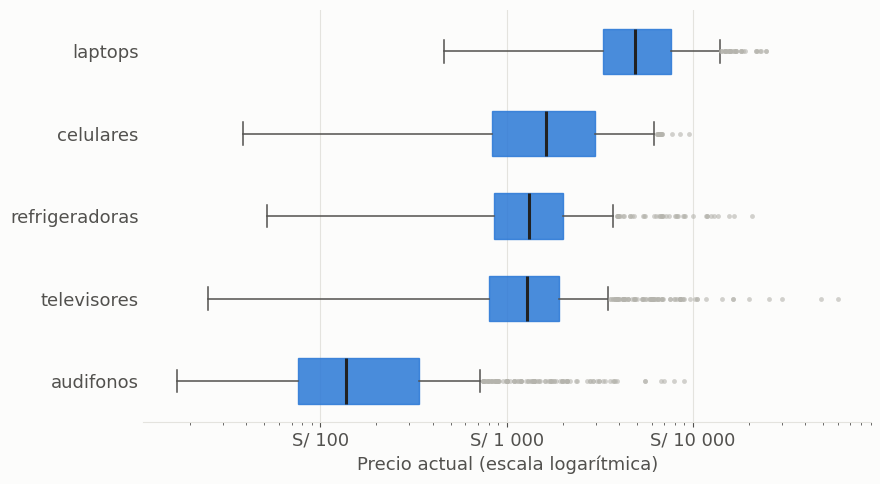

In [7]:
orden = limpio.groupby("categoria")["precio_actual"].median().sort_values().index
grupos = [limpio.loc[limpio["categoria"] == c, "precio_actual"] for c in orden]

fig, ax = plt.subplots(figsize=TAM)
ax.boxplot(grupos, vert=False, widths=0.55, patch_artist=True,
           medianprops=dict(color=TEXTO, linewidth=2.2),
           boxprops=dict(facecolor=AZUL, edgecolor=AZUL, alpha=0.85),
           whiskerprops=dict(color=TEXTO_2, linewidth=1.1),
           capprops=dict(color=TEXTO_2, linewidth=1.1),
           flierprops=dict(marker="o", markersize=3.5, markerfacecolor=GRIS, markeredgecolor="none", alpha=0.6))
ax.set_yticks(range(1, len(orden) + 1))
ax.set_yticklabels(orden)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"S/ {x:,.0f}".replace(",", " ")))
ax.set_xlabel("Precio actual (escala logarítmica)")
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
guardar(fig, "boxplot_precios_categoria.png")

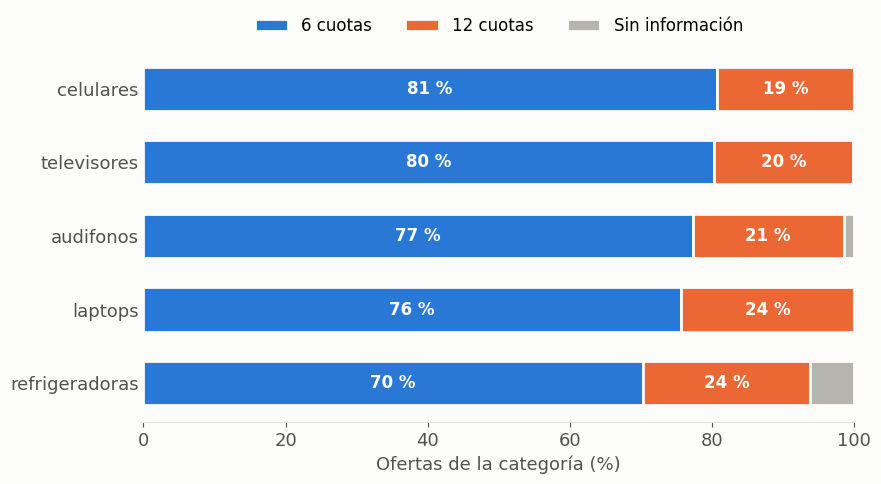

In [8]:
tabla = (limpio.assign(cuotas=limpio["numero_cuotas"].map({6: "6 cuotas", 12: "12 cuotas"}).fillna("Sin información"))
         .pivot_table(index="categoria", columns="cuotas", values="id_publicacion", aggfunc="count", fill_value=0))
tabla = tabla[["6 cuotas", "12 cuotas", "Sin información"]]
porc = tabla.div(tabla.sum(axis=1), axis=0) * 100
porc = porc.loc[porc["6 cuotas"].sort_values().index]
colores = {"6 cuotas": AZUL, "12 cuotas": NARANJA, "Sin información": GRIS}

fig, ax = plt.subplots(figsize=TAM)
izq = np.zeros(len(porc))
for col in porc.columns:
    ax.barh(porc.index, porc[col], left=izq, color=colores[col], height=0.6, edgecolor=FONDO, linewidth=2, label=col)
    for y, (x0, w) in enumerate(zip(izq, porc[col])):
        if w >= 8:
            ax.text(x0 + w / 2, y, f"{w:.0f} %", ha="center", va="center", fontsize=T - 1, color="white", fontweight="bold")
    izq += porc[col].values
ax.set_xlim(0, 100)
ax.set_xlabel("Ofertas de la categoría (%)")
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), fontsize=T - 1)
guardar(fig, "cuotas_por_categoria.png")

In [9]:
resumen = pd.Series({
    "registros_crudos": len(crudo),
    "ofertas_finales": len(limpio),
    "columnas": limpio.shape[1],
    "paginas": crudo["url_fuente"].nunique(),
    "minutos": round((crudo["fecha_extraccion"].max() - crudo["fecha_extraccion"].min()).total_seconds() / 60, 1),
    "pct_con_cuotas": round(limpio["numero_cuotas"].notna().mean() * 100, 1),
    "mediana_laptops_vs_audifonos": round(medianas["laptops"] / medianas["audifonos"], 1),
})
resumen

registros_crudos                5080.0
ofertas_finales                 4412.0
columnas                          14.0
paginas                           95.0
minutos                           28.8
pct_con_cuotas                    98.8
mediana_laptops_vs_audifonos      35.5
dtype: float64

In [10]:
sorted(p.name for p in FIGURAS.glob("*.png"))

['boxplot_precios_categoria.png',
 'cuotas_por_categoria.png',
 'embudo_limpieza.png',
 'nulos_por_columna.png',
 'precio_mediano_categoria.png',
 'progreso_extraccion.png']